# MEN 04 — Motion energy in the first 150 ms after the go cue: maps by pixel

`men_00` §9b shows bottom-camera ME rising ~12 ms after the go cue and then oscillating at about
30 Hz (peaks near 25 and 55 ms), far faster than licking. This notebook finds where in the image
that motion is.

Method: for each go cue, the video frames from 60 ms before to 160 ms after it are cut frame-exactly
from the session's MP4 (library `video_alignment.event_frame_ranges` on the ME table's corrected
`harp_time`, then `video_clips.cut_clips`). The absolute difference between consecutive frames is
averaged over cues pixel by pixel, giving one map per 2 ms frame. Each session's clips must
reproduce the ME table's `me_clean` at a frame offset of 0 (`cue_me_maps.cue_maps`).

The clips are re-encoded (x264), and every clip starts on the same encoder frame type, so clip ME
carries a 4-frame (8 ms) cycle, 10–25% deep, that is the same in every clip and survives averaging
over cues. The maps are therefore averaged over 4 consecutive frames (`cm.smooth_encoder_cycle`),
which cancels it and keeps ~91% of a 30 Hz rhythm. Timing (§1, §4) comes from the ME table, computed
on the original video.

ME is the size of the frame-to-frame change, so a body part moving forward and back gives two ME
peaks per cycle: an ME rhythm at f Hz is a movement at about f/2 Hz.

1. Cue-triggered ME at 500 Hz in every session: the early jump and the fast part, per mouse
2. Maps after the go cue, one session per mouse
3. ME by image region
4. Timing of the fast peaks
5. Numbers

## Setup

In [1]:
import os
import warnings
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

import fip_utils as fu
import men_utils as mu
import signal_utils as su
import stats_utils as st
import cue_me_maps as cm
from plotstyle import apply_style, style_ax, save_fig, PALETTE, OKABE_ITO

apply_style()
warnings.filterwarnings("ignore", message="Mean of empty slice")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

In [2]:
IS_CO = os.path.isdir("/root/capsule")

# Same sources and cache as men_00 (the cache key must match men_00's call to be reused)
ASSET_CANDIDATES = {
    "3ch": ["/root/capsule/data/DANE_3channels_curated",
            "../../data/results-a278f830-9bf2-48e8-9928-a2ff78e4818f"],
    "4ch": ["/root/capsule/data/DANE_4channels_curated",
            "../../data/results-ddcccb0f-f18f-44a6-a2b1-caba680d28a1"],
}
ME_DATA_ROOT = "/root/capsule/data" if IS_CO else os.environ.get("ME_DATA_ROOT", "../../data")
CACHE_PATH = ("/root/capsule/scratch/men_00/sessions.pkl" if IS_CO
              else os.environ.get("MEN_CACHE", "../../data/men_00_cache/sessions.pkl"))
# Clips and per-session maps (cut once, then reused)
CLIP_DIR = "/root/capsule/scratch/men_04" if IS_CO else "../../data/men_04_cache"
FIG_DIR = "/root/capsule/scratch/figures/men" if IS_CO else "../data/figures/men"
SAVE_FIG = True

CAMERAS = ("BottomCamera", "SideCameraRight")   # men_00's cache call
CAM = "BottomCamera"
FS = 100.0                                      # men_00's grid (only for the cache key)

# ── §1: cue-triggered ME from the table, 500 Hz ──────────────────────────────
TRACE_LAGS = np.arange(-0.05, 0.15 + 1e-9, 0.002)
JUMP_WIN_MS = (10, 16)     # the early jump
FAST_WIN_MS = (20, 110)    # where the fast part is measured
SMOOTH_MS = 16.0           # fast part = trace minus its running mean over this

# ── §2–4: maps ───────────────────────────────────────────────────────────────
N_CUES = 100               # go cues per session, sampled at random (seed 0)
BEFORE_S, AFTER_S = 0.06, 0.16
N_WORKERS = 3              # sessions cut in parallel
MAP_WINDOWS_MS = [(10, 16), (18, 30), (50, 62), (100, 150)]
BAND_HZ = (22, 45)         # band of the per-pixel fast-power map

## 0. Data

In [3]:
asset_roots = {name: root for name, cands in ASSET_CANDIDATES.items()
               if (root := fu.find_asset_root(cands))}
me_index = fu.load_me_index(ME_DATA_ROOT)
inv = mu.inventory_sessions(asset_roots, me_index)
inv["has_trials"] = inv["path"].notna()
sessions = mu.load_sessions(inv[inv.has_trials], fs=FS, cache_path=CACHE_PATH,
                            data_root=ME_DATA_ROOT, cameras=CAMERAS)
used = set(inv.loc[inv[f"{CAM}_status"] == "ok", "ses_idx"])
sessions = [s for s in sessions if s["session"] in used]
cam_rows = me_index[(me_index.camera == CAM) & (me_index.status == "ok")].set_index("ses_idx")
print(f"{len(sessions)} sessions with a usable {CAM}, {len({s['subject'] for s in sessions})} mice")

loaded 97 sessions from cache ../../data/men_00_cache/sessions.pkl
88 sessions with a usable BottomCamera, 9 mice


## 1. Cue-triggered ME at 500 Hz in every session

The ME table's full-rate trace, z-scored over the task as in `men_00` §9b, averaged over all go cues
and separately over responded and no-response trials. Two numbers per session:

- **jump**: mean over 10–16 ms after the cue minus the mean over −50–0 ms (z);
- **fast**: SD over 20–110 ms of the trace minus its 16 ms running mean (z).

In [4]:
def fast_sd(trace):
    lags_ms = TRACE_LAGS * 1000
    w = (lags_ms >= FAST_WIN_MS[0]) & (lags_ms <= FAST_WIN_MS[1])
    return float(np.std(cm.fast_component(trace, TRACE_LAGS[1] - TRACE_LAGS[0], SMOOTH_MS)[w]))


def jump(trace):
    lags_ms = TRACE_LAGS * 1000
    return float(trace[(lags_ms >= JUMP_WIN_MS[0]) & (lags_ms <= JUMP_WIN_MS[1])].mean()
                 - trace[lags_ms < 0].mean())


rows = []
for s in sessions:
    t_me, y, _ = fu.motion_energy_to_session(s["session"], s["trials"], camera=CAM, data_root=ME_DATA_ROOT)
    fs_me = 1 / np.median(np.diff(t_me))
    z = su.zscore(y)
    tr = s["trials"]
    for cond, m in (("all", np.ones(len(tr), bool)), ("responded", tr["animal_response"] != 2),
                    ("no response", tr["animal_response"] == 2)):
        cues = tr.loc[m, "goCue_start_time_in_session"].dropna().to_numpy()
        if len(cues) < 5:
            continue
        trace = np.nanmean(su.peri_event_grid(z, t_me[0], fs_me, cues, TRACE_LAGS), axis=0)
        rows.append(dict(subject=s["subject"], session=s["session"], cond=cond, n=len(cues),
                         trace=trace, jump=jump(trace), fast=fast_sd(trace)))
cue_me = pd.DataFrame(rows)
per_mouse = (cue_me[cue_me.cond == "all"].groupby("subject")[["jump", "fast"]].mean()
             .sort_values("jump", ascending=False))
MICE = per_mouse.index.tolist()          # sorted by the early jump, largest first
per_mouse.round(2)

,jump,fast
subject,,
809487,1.34,0.08
816214,1.02,0.08
808054,0.93,0.08
816212,0.63,0.08
809491,0.41,0.07
818585,0.11,0.05
818586,0.04,0.04
800886,0.03,0.06
815334,-0.01,0.02


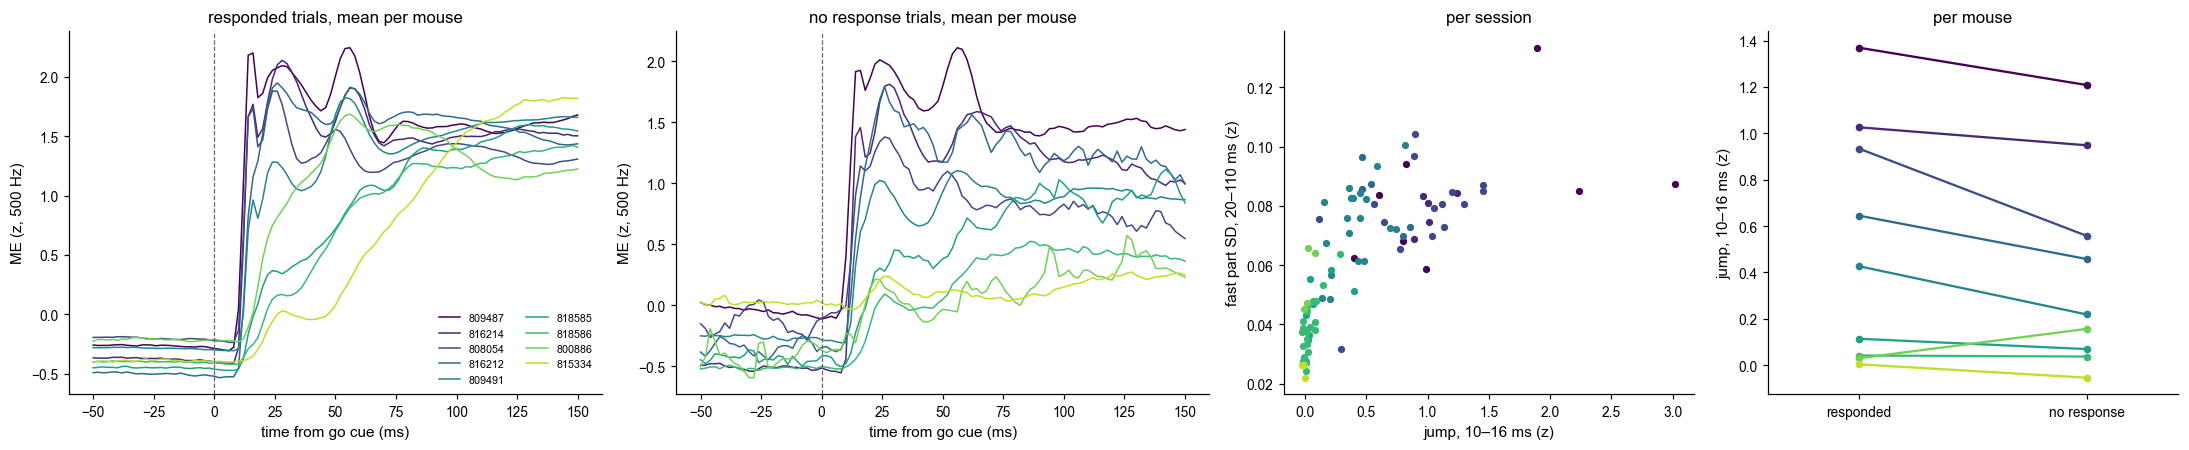

In [5]:
mouse_color = dict(zip(MICE, plt.get_cmap("viridis")(np.linspace(0, 0.9, len(MICE)))))
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2), gridspec_kw=dict(width_ratios=[1.3, 1.3, 1, 1]))
lags_ms = TRACE_LAGS * 1000
for ax, cond in zip(axes[:2], ("responded", "no response")):
    for mouse in MICE:
        sel = cue_me[(cue_me.cond == cond) & (cue_me.subject == mouse)]
        if len(sel):
            ax.plot(lags_ms, np.mean(np.stack(sel.trace), 0), color=mouse_color[mouse], lw=1, label=mouse)
    ax.axvline(0, color=PALETTE["neutral"], ls="--", lw=0.8)
    ax.set(xlabel="time from go cue (ms)", ylabel="ME (z, 500 Hz)", title=f"{cond} trials, mean per mouse")
    style_ax(ax)
axes[0].legend(fontsize=7, ncol=2)

ax = axes[2]
sel = cue_me[cue_me.cond == "all"]
for mouse in MICE:
    m = sel.subject == mouse
    ax.scatter(sel.loc[m, "jump"], sel.loc[m, "fast"], color=mouse_color[mouse], s=14)
ax.set(xlabel="jump, 10–16 ms (z)", ylabel="fast part SD, 20–110 ms (z)", title="per session")
style_ax(ax)

ax = axes[3]
paired = (cue_me[cue_me.cond != "all"].groupby(["subject", "session", "cond"])["jump"].mean()
          .groupby(["subject", "cond"]).mean().unstack("cond").reindex(MICE))
for mouse, r in paired.iterrows():
    ax.plot([0, 1], [r["responded"], r["no response"]], color=mouse_color[mouse], marker="o", ms=4)
ax.set_xticks([0, 1], ["responded", "no response"])
ax.set(xlim=(-0.4, 1.4), ylabel="jump, 10–16 ms (z)", title="per mouse")
style_ax(ax)
fig.tight_layout()
save_fig(fig, "men04_1_cue_me_500hz", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

## 2. Maps after the go cue, one session per mouse

For each mouse the session whose fast part (§1) is closest to the mouse's median. Rows are mice,
largest early jump first. Columns: the mean frame with the regions of §3 filled in; the mean
|frame difference| in four lag windows minus its mean before the cue (one colour scale per row); and
per-pixel power of the fast part (trace minus 16 ms running mean, 15–110 ms) at 22–45 Hz.

The first run cuts the clips (about 5 s per cue); later runs read the cached maps.

In [6]:
pick = (cue_me[cue_me.cond == "all"].assign(
            d=lambda d: (d.fast - d.groupby("subject").fast.transform("median")).abs())
        .sort_values("d").groupby("subject").head(1).set_index("subject").reindex(MICE))
by_session = {s["session"]: s for s in sessions}


def session_maps(ses_idx):
    row = cam_rows.loc[ses_idx]
    harp, me = cm.load_frame_table(ME_DATA_ROOT, row["session"], CAM)
    cues = by_session[ses_idx]["trials"]["goCue_start_time_raw"].dropna().to_numpy()
    return cm.cue_maps(cm.video_url(row), harp, me, cues, N_CUES, BEFORE_S, AFTER_S, seed=0,
                       clip_dir=os.path.join(CLIP_DIR, "clips"), prefix=f"{ses_idx}_{CAM}",
                       cache_path=os.path.join(CLIP_DIR, f"maps_{ses_idx}_{CAM}.npz"))


with ThreadPoolExecutor(N_WORKERS) as pool:
    maps = dict(zip(MICE, pool.map(session_maps, pick["session"])))
for r in maps.values():
    r["maps"] = cm.smooth_encoder_cycle(r["maps"])
align = pd.DataFrame({mouse: dict(session=pick.loc[mouse, "session"], cues=len(r["clip_me"]),
                                  r_at_0=r["align_r"][r["align_shifts"] == 0][0],
                                  r_at_pm1=r["align_r"][np.abs(r["align_shifts"]) == 1].max())
                      for mouse, r in maps.items()}).T
align

,session,cues,r_at_0,r_at_pm1
809487,809487_2025-09-24,100,0.980089,0.928187
816214,816214_2025-12-01,100,0.988984,0.889731
808054,808054_2025-09-15,100,0.981943,0.904759
816212,816212_2025-11-26,77,0.995615,0.81318
809491,809491_2025-10-23,100,0.977301,0.929906
818585,818585_2025-12-15,100,0.98204,0.912135
818586,818586_2026-01-27,100,0.981577,0.476523
800886,800886_2025-09-05,100,0.950517,0.884361
815334,815334_2025-11-14,100,0.968688,0.939107


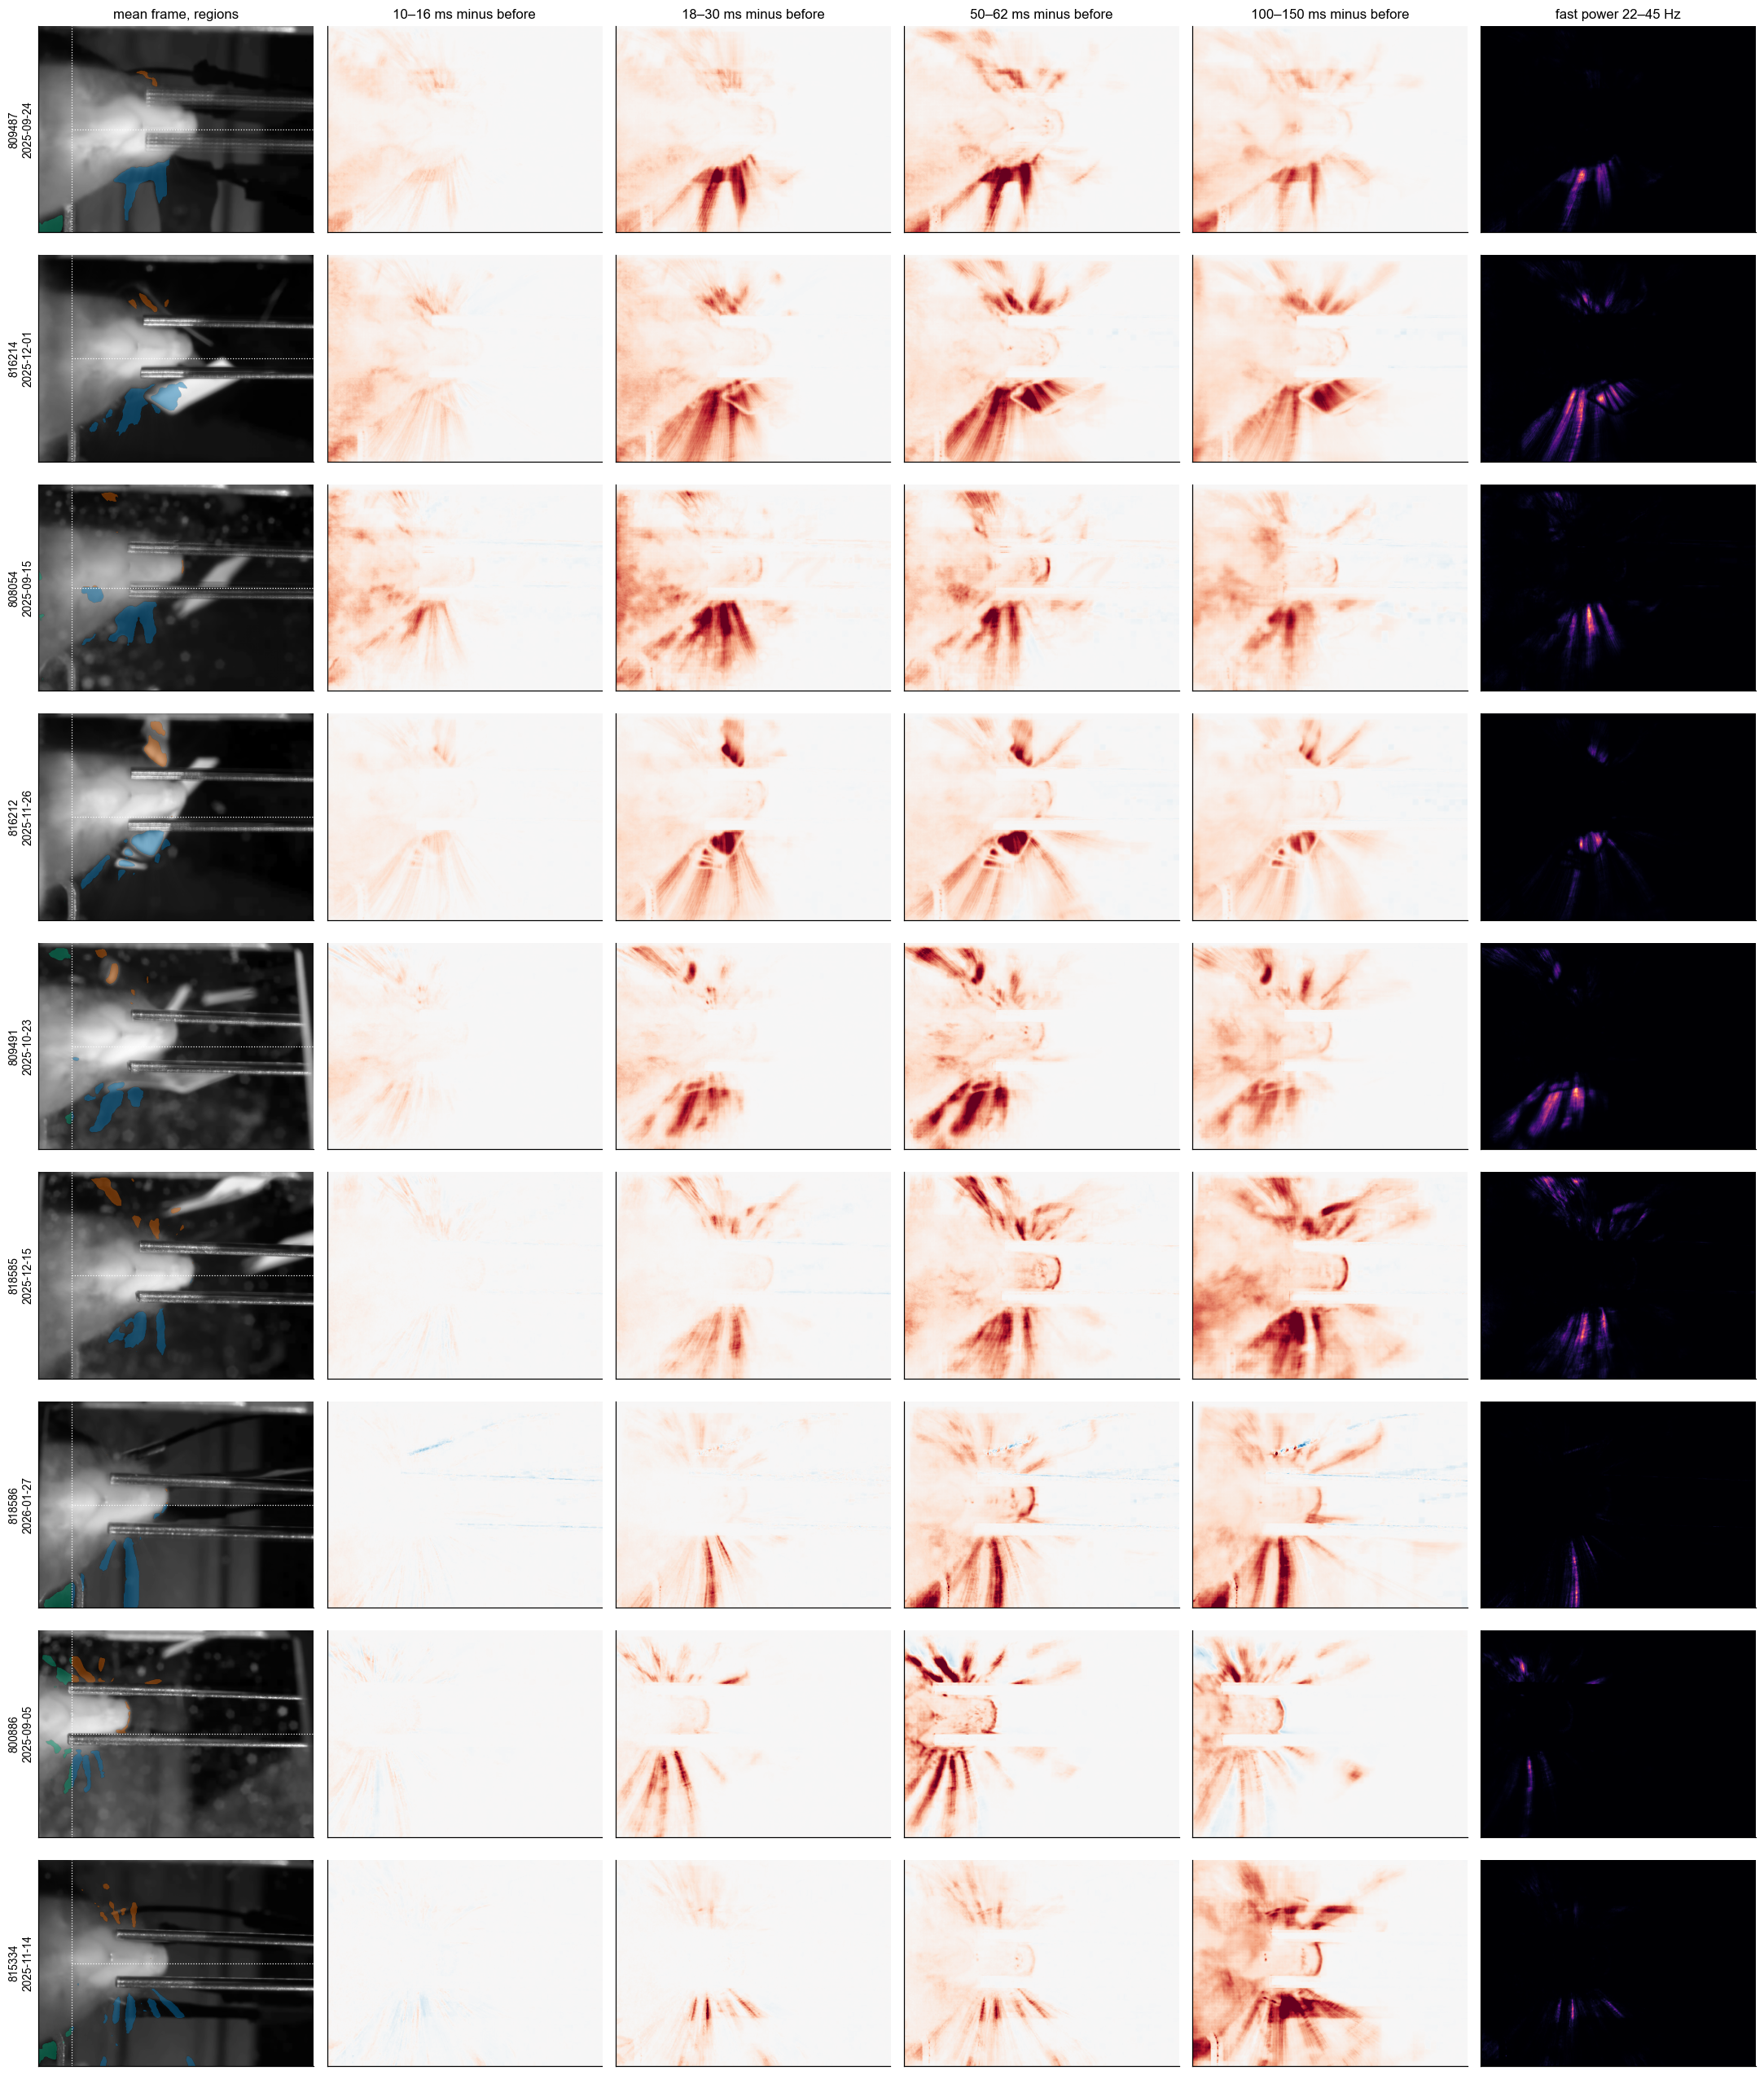

In [7]:
masks = {mouse: cm.region_masks(r["maps"], r["lags_s"]) for mouse, r in maps.items()}
n_col = 2 + len(MAP_WINDOWS_MS)
fig, axes = plt.subplots(len(MICE), n_col, figsize=(3.3 * n_col, 2.6 * len(MICE)))
for i, mouse in enumerate(MICE):
    r = maps[mouse]
    exc = cm.excess_maps(r["maps"], r["lags_s"], MAP_WINDOWS_MS)
    vmax = np.nanpercentile(np.abs(exc), 99.8)
    cm.draw_regions(axes[i, 0], r["reference"], masks[mouse])
    axes[i, 0].set_ylabel(f"{mouse}\n{pick.loc[mouse, 'session'][7:]}", fontsize=9)
    for ax, (a, b), e in zip(axes[i, 1:], MAP_WINDOWS_MS, exc):
        ax.imshow(e, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
        if i == 0:
            ax.set_title(f"{a}–{b} ms minus before")
    axes[i, -1].imshow(cm.band_power_map(r["maps"], r["lags_s"], band_hz=BAND_HZ, smooth_ms=SMOOTH_MS),
                       cmap="magma")
    for ax in axes[i]:
        ax.set_xticks([])
        ax.set_yticks([])
axes[0, 0].set_title("mean frame, regions")
axes[0, -1].set_title(f"fast power {BAND_HZ[0]}–{BAND_HZ[1]} Hz")
fig.tight_layout()
save_fig(fig, "men04_2_maps", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

## 3. ME by image region

Regions per session (`cm.region_masks`): the 3% of pixels with the largest mean |difference|
10–80 ms after the cue (minus before, blurred by 2 px), split at 12% of the width into the left edge of the frame
(the face and body edge) and the rest, which is split at mid-height into the upper and lower half
(mostly the whiskers on either side of the snout; in some sessions also bright objects next to the
spouts). The fourth region is every other pixel. Traces are the region's mean |difference| minus
its pre-cue mean (luma units); a region with no pixels is left out (NaN).

/Users/mib/Documents/Code/kinematics_analysis/.venv-fip/lib/python3.12/site-packages/numpy/_core/_methods.py:130: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


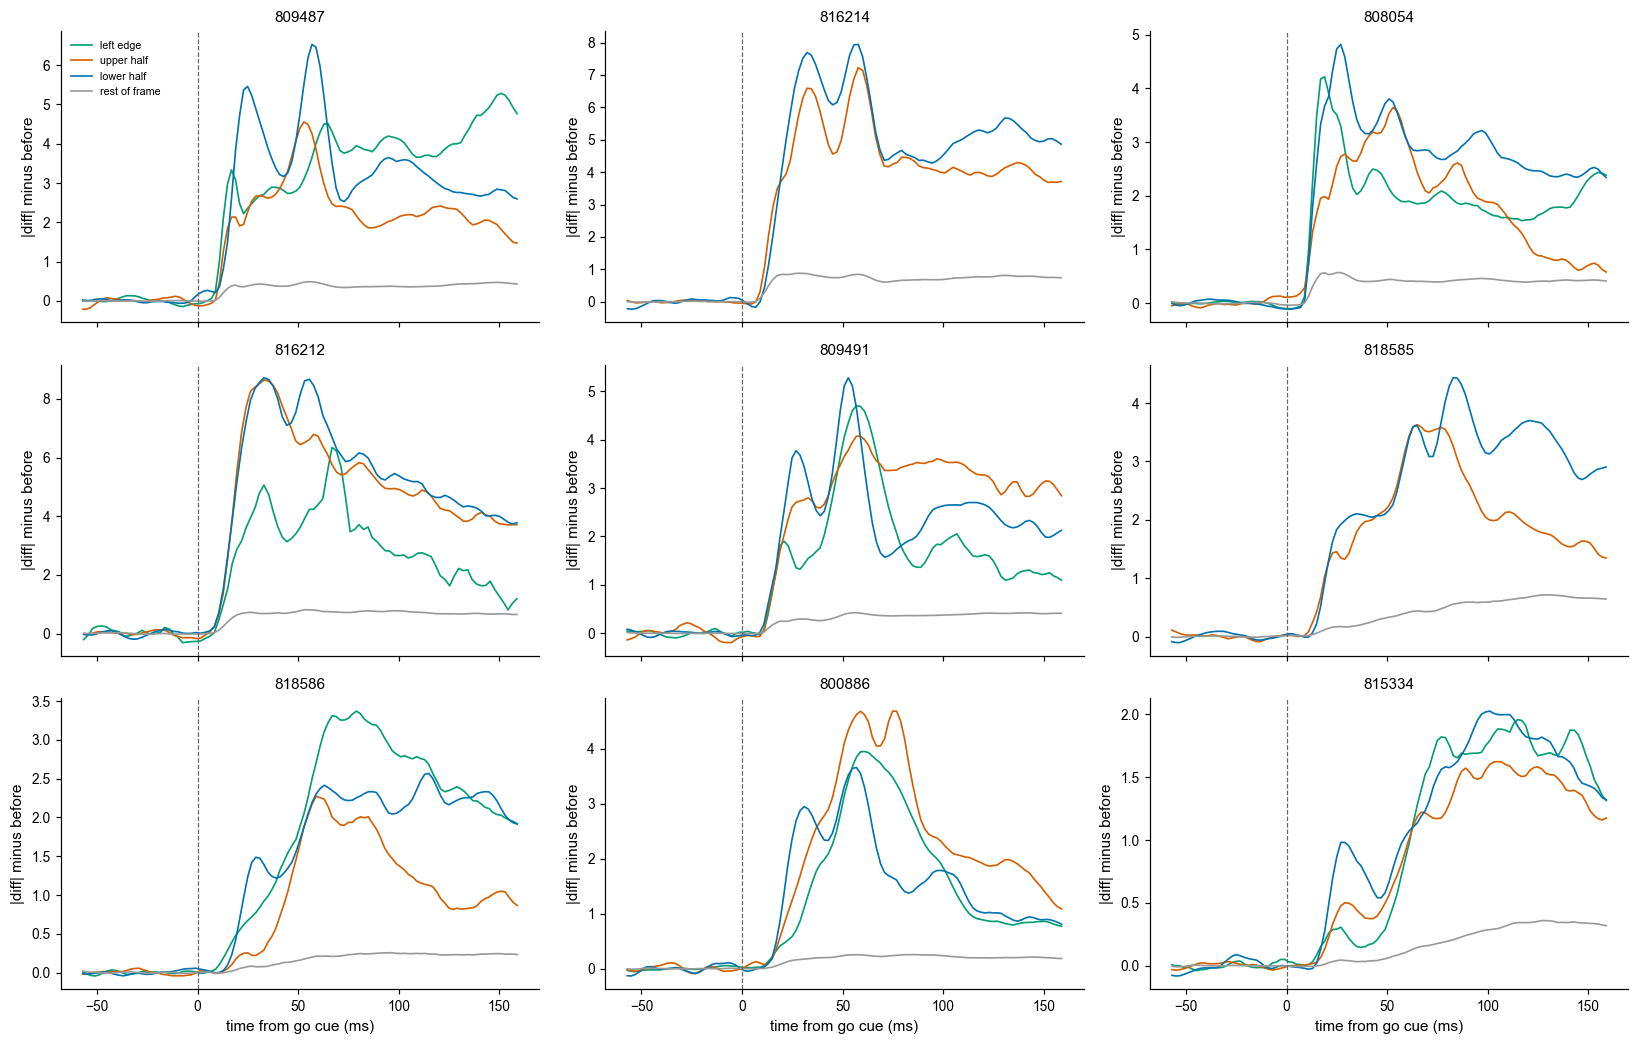

jump_frac                                     fast_frac                                    
region  left edge lower half rest of frame upper half left edge lower half rest of frame upper half
subject                                                                                            
809487       0.39       0.14          0.42       0.26      0.03       0.07          0.03       0.04
816214        NaN       0.15          0.56       0.28       NaN       0.04          0.02       0.04
808054       0.53       0.35          0.52       0.34      0.03       0.04          0.02       0.04
816212       0.16       0.19          0.31       0.18      0.06       0.03          0.02       0.03
809491       0.09       0.11          0.22       0.11      0.04       0.06          0.03       0.03
818585        NaN       0.02          0.05       0.07       NaN       0.04          0.01       0.03
818586       0.06       0.02          0.01       0.01      0.02       0.04          0.02       0.03
800886       0.03       0.03          0.06       0.02      0.03       0.05          0.03       0.04
815334       0.02      -0.00         -0.01       0.01      0.02       0.03          0.01       0.03

In [8]:
fig, axes = plt.subplots(int(np.ceil(len(MICE) / 3)), 3, figsize=(15, 3.2 * np.ceil(len(MICE) / 3)),
                         sharex=True)
region_rows = []
for ax, mouse in zip(axes.ravel(), MICE):
    r = maps[mouse]
    lags_ms = r["lags_s"] * 1000
    dt = float(np.median(np.diff(r["lags_s"])))
    for name, m in masks[mouse].items():
        trace = r["maps"][:, m].mean(1)
        trace = trace - trace[lags_ms < 0].mean()
        ax.plot(lags_ms, trace, color=cm.REGION_COLORS[name], lw=1.1, label=name)
        fast = cm.fast_component(trace, dt, SMOOTH_MS)
        w = (lags_ms >= FAST_WIN_MS[0]) & (lags_ms <= FAST_WIN_MS[1])
        region_rows.append(dict(subject=mouse, region=name, pixels=int(m.sum()),
                                jump=trace[(lags_ms >= JUMP_WIN_MS[0]) & (lags_ms <= JUMP_WIN_MS[1])].mean(),
                                peak=trace[lags_ms > 0].max(), fast=fast[w].std()))
    ax.axvline(0, color=PALETTE["neutral"], ls="--", lw=0.8)
    ax.set_title(mouse, fontsize=10)
    ax.set_ylabel("|diff| minus before")
    style_ax(ax)
for ax in axes.ravel()[len(MICE):]:
    ax.axis("off")
for ax in axes[-1]:
    ax.set_xlabel("time from go cue (ms)")
axes.ravel()[0].legend(fontsize=7)
fig.tight_layout()
save_fig(fig, "men04_3_regions", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

regions = pd.DataFrame(region_rows)
# Jump and fast part relative to the region's own peak, so regions of different size compare
regions["jump_frac"] = regions.jump / regions.peak
regions["fast_frac"] = regions.fast / regions.peak
regions.pivot(index="subject", columns="region", values=["jump_frac", "fast_frac"]).reindex(MICE).round(2)

## 4. Timing of the fast peaks

From the ME table (original video, every cue of every session) rather than the clips: each mouse's
mean of its session traces from §1 (all trials), minus its 16 ms running mean. Peaks 20–110 ms after
the cue count if their prominence is over 4 times the SD of the same fast part before the cue.
Intervals between successive peaks give the ME rhythm; the movement's rate is about half of it.

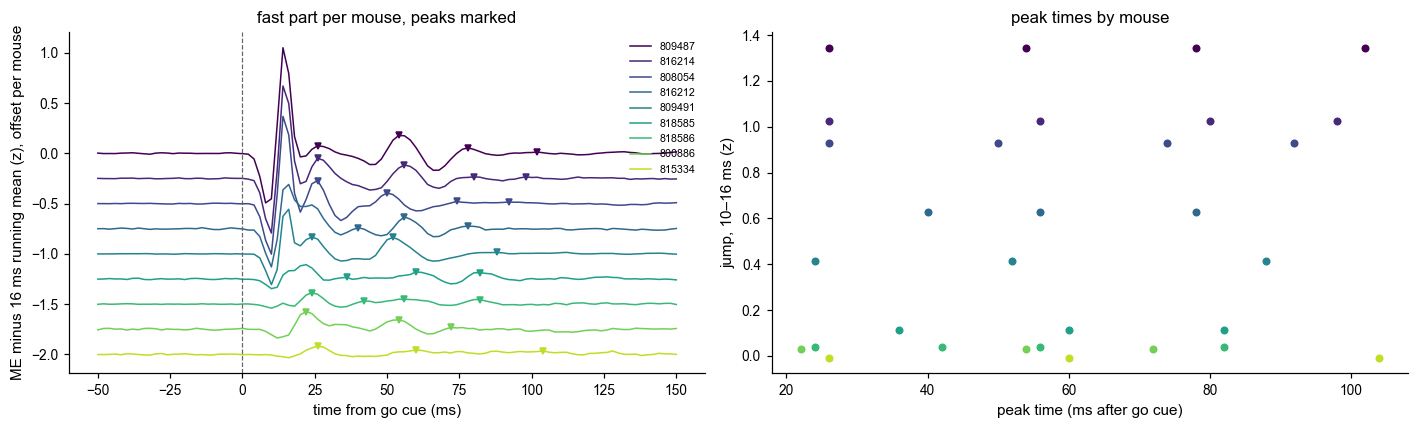

,jump,noise_sd,peaks_ms,interval_ms,me_rhythm_hz
subject,,,,,
809487,1.345,0.003,"[26, 54, 78, 102]",24.0,41.667
816214,1.024,0.003,"[26, 56, 80, 98]",24.0,41.667
808054,0.929,0.002,"[26, 50, 74, 92]",24.0,41.667
816212,0.626,0.005,"[40, 56, 78]",19.0,52.632
809491,0.414,0.001,"[24, 52, 88]",32.0,31.250
818585,0.111,0.004,"[36, 60, 82]",23.0,43.478
818586,0.038,0.002,"[24, 42, 56, 82]",18.0,55.556
800886,0.030,0.006,"[22, 54, 72]",25.0,40.000
815334,-0.008,0.004,"[26, 60, 104]",39.0,25.641


In [9]:
lags_ms = TRACE_LAGS * 1000
dt = TRACE_LAGS[1] - TRACE_LAGS[0]
w = (lags_ms >= FAST_WIN_MS[0]) & (lags_ms <= FAST_WIN_MS[1])
peak_rows = []
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for k, mouse in enumerate(MICE):
    trace = np.mean(np.stack(cue_me[(cue_me.cond == "all") & (cue_me.subject == mouse)].trace), 0)
    fast = cm.fast_component(trace, dt, SMOOTH_MS)
    noise = fast[lags_ms < 0].std()
    idx, _ = find_peaks(fast[w], prominence=4 * noise)
    times = lags_ms[w][idx]
    peak_rows.append(dict(subject=mouse, jump=per_mouse.loc[mouse, "jump"], noise_sd=noise,
                          peaks_ms=np.round(times).astype(int).tolist(),
                          interval_ms=float(np.median(np.diff(times))) if len(times) > 1 else np.nan))
    axes[0].plot(lags_ms, fast - 0.25 * k, color=mouse_color[mouse], lw=1, label=mouse)
    axes[0].plot(times, fast[w][idx] - 0.25 * k, "v", color=mouse_color[mouse], ms=4)
axes[0].axvline(0, color=PALETTE["neutral"], ls="--", lw=0.8)
axes[0].set(xlabel="time from go cue (ms)", ylabel="ME minus 16 ms running mean (z), offset per mouse",
            title="fast part per mouse, peaks marked")
axes[0].legend(fontsize=7, loc="upper right")
style_ax(axes[0])
peaks = pd.DataFrame(peak_rows).set_index("subject")
peaks["me_rhythm_hz"] = 1000 / peaks.interval_ms
ax = axes[1]
for mouse, r in peaks.iterrows():
    ax.scatter(r.peaks_ms, np.full(len(r.peaks_ms), r.jump), color=mouse_color[mouse], s=18)
ax.set(xlabel="peak time (ms after go cue)", ylabel="jump, 10–16 ms (z)", title="peak times by mouse")
style_ax(ax)
fig.tight_layout()
save_fig(fig, "men04_4_peak_timing", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()
peaks.round(3)

## 5. Numbers

In [10]:
ring = per_mouse.join(regions.pivot(index="subject", columns="region", values="fast_frac")
                      .add_prefix("fast_frac: "))
print(f"§1  {len(cue_me[cue_me.cond == 'all'])} sessions, {len(MICE)} mice; per-mouse jump 10–16 ms "
      f"{per_mouse.jump.min():.2f}–{per_mouse.jump.max():.2f} z, fast part SD "
      f"{per_mouse.fast.min():.2f}–{per_mouse.fast.max():.2f} z")
d = paired["responded"] - paired["no response"]
m, p, n = st.wilcoxon_animals(d)
print(f"§1  jump, responded − no response: {m:+.2f} z (Wilcoxon p = {p:.3g}, n = {n} mice)")
print(f"§2  clips match the ME table at offset 0 in every session: r {align.r_at_0.min():.3f}–"
      f"{align.r_at_0.max():.3f} (±1 frame at most {align.r_at_pm1.max():.3f})")
whisk = regions[regions.region.isin(["upper half", "lower half"])].groupby("subject").fast_frac.mean()
edge = regions[regions.region == "left edge"].set_index("subject").fast_frac
print(f"§3  fast part / peak, whisker halves {whisk.median():.2f} vs left edge {edge.median():.2f} "
      f"(median over mice)")
ringing = peaks[peaks.jump > 0.3]
print(f"§4  mice with a jump > 0.3 z ({len(ringing)}): median peak interval "
      f"{ringing.interval_ms.median():.0f} ms, ME rhythm {ringing.me_rhythm_hz.median():.0f} Hz "
      f"(movement ~{ringing.me_rhythm_hz.median() / 2:.0f} Hz)")
ring.round(2)

§1  88 sessions, 9 mice; per-mouse jump 10–16 ms -0.01–1.34 z, fast part SD 0.02–0.08 z
§1  jump, responded − no response: +0.11 z (Wilcoxon p = 0.0391, n = 9 mice)
§2  clips match the ME table at offset 0 in every session: r 0.951–0.996 (±1 frame at most 0.939)
§3  fast part / peak, whisker halves 0.04 vs left edge 0.03 (median over mice)
§4  mice with a jump > 0.3 z (5): median peak interval 24 ms, ME rhythm 42 Hz (movement ~21 Hz)


,jump,fast,fast_frac: left edge,fast_frac: lower half,fast_frac: rest of frame,fast_frac: upper half
subject,,,,,,
809487,1.34,0.08,0.03,0.07,0.03,0.04
816214,1.02,0.08,NaN,0.04,0.02,0.04
808054,0.93,0.08,0.03,0.04,0.02,0.04
816212,0.63,0.08,0.06,0.03,0.02,0.03
809491,0.41,0.07,0.04,0.06,0.03,0.03
818585,0.11,0.05,NaN,0.04,0.01,0.03
818586,0.04,0.04,0.02,0.04,0.02,0.03
800886,0.03,0.06,0.03,0.05,0.03,0.04
815334,-0.01,0.02,0.02,0.03,0.01,0.03
